### Import dan setup path

In [1]:
import os
import re
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

current = Path(os.getcwd())
if (current / "data").exists():
    BASE_DIR = current
elif (current.parent / "data").exists():
    BASE_DIR = current.parent
else:
    raise FileNotFoundError("Folder 'data' tidak ditemukan, cek lokasi notebook")

CLEAN_DIR = BASE_DIR / "data" / "clean"
ANALYTICS_DIR = BASE_DIR / "data" / "analytics"
ANALYTICS_DIR.mkdir(parents=True, exist_ok=True)

### Read data text

In [2]:
df_teks = pd.read_csv(CLEAN_DIR / "teks_mahasiswa_clean.csv")
df_teks = df_teks.dropna(subset=["teks_komentar"]).reset_index(drop=True)

print("Jumlah komentar:", len(df_teks))
df_teks.head()

Jumlah komentar: 314


,response_id,jenis_pertanyaan,teks_komentar
0,MHS_0001,saran_perbaikan,PARKIRANN menurutku terlalu sempit
1,MHS_0005,saran_perbaikan,MOHON PARKIRAN NYA MUNGKIN BISA DIBICARAKAN LAGI
2,MHS_0006,saran_perbaikan,"Parkiran, dikarenakan mahasiswa di PENS banyak..."
3,MHS_0007,saran_perbaikan,Menurut saya dengan penambahan kuota mahasiswa...
4,MHS_0008,saran_perbaikan,parkiran motor tentunya karena kapasitas kenda...


### Function text processing

In [3]:
stemmer = StemmerFactory().create_stemmer()
stopword_sastrawi = StopWordRemoverFactory().get_stop_words()
stopword_tambahan = ["tolong", "mohon", "kak", "nya", "sih", "deh", "dong", "kok", "ya", "dll", "dsb"]
daftar_stopword = set(stopword_sastrawi + stopword_tambahan)

# kamus normalisasi kata tidak baku
kamus_slang = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak", "tdk": "tidak",
    "yg": "yang", "dgn": "dengan", "utk": "untuk", "krn": "karena", "karna": "karena",
    "udh": "sudah", "udah": "sudah", "sdh": "sudah", "blm": "belum", "bgt": "banget",
    "bs": "bisa", "jd": "jadi", "sm": "sama", "dr": "dari", "tp": "tapi", "aja": "saja",
    "mhs": "mahasiswa", "dsn": "dosen", "perpus": "perpustakaan"
}

cache_stem = {}

def stem_kata(kata):
    # cache supaya kata yang sama tidak di-stem berulang (stemming Sastrawi lambat)
    if kata not in cache_stem:
        cache_stem[kata] = stemmer.stem(kata)
    return cache_stem[kata]

def preprocessing_teks(teks):
    # 1. case folding
    teks = str(teks).lower()

    # 2. cleaning
    teks = teks.replace("wi-fi", "wifi").replace("wi fi", "wifi")
    teks = re.sub(r"http\S+", " ", teks)
    teks = re.sub(r"[^a-z\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()

    # 3. tokenization
    kata_kata = teks.split()

    # 4. normalisasi
    kata_kata = [kamus_slang.get(k, k) for k in kata_kata]

    # 5. stopword removal
    kata_kata = [k for k in kata_kata if k not in daftar_stopword and len(k) > 1]

    # 6. stemming
    kata_kata = [stem_kata(k) for k in kata_kata]

    return kata_kata

### Terapkan processing

In [4]:
df_teks["token"] = df_teks["teks_komentar"].apply(preprocessing_teks)
df_teks["teks_bersih"] = df_teks["token"].apply(lambda t: " ".join(t))

df_teks[["teks_komentar", "teks_bersih"]].head(10)

,teks_komentar,teks_bersih
0,PARKIRANN menurutku terlalu sempit,parkirann turut terlalu sempit
1,MOHON PARKIRAN NYA MUNGKIN BISA DIBICARAKAN LAGI,parkir mungkin bicara
2,"Parkiran, dikarenakan mahasiswa di PENS banyak...",parkir karena mahasiswa pens banyak besar parkir
3,Menurut saya dengan penambahan kuota mahasiswa...,tambah kuota mahasiswa keeprluan alat praktiku...
4,parkiran motor tentunya karena kapasitas kenda...,parkir motor tentu kapasitas kendara mahasiswa...
5,"Toilet dibersihkan lagi, dan pelayanan baak di...",toilet bersih layan baak baik pegawai judes ra...
6,"di lab, ada bbrp alat yg tidak berfungsi\neepi...",lab bbrp alat fungsi eepiswlan jdi lot makin b...
7,1. tempat parkir saran perbaikan,tempat parkir saran baik
8,Fasilitas Lab Dimana alat tergolong JADUL dan ...,fasilitas lab alat golong jadul banyak rusak s...
9,Parkir D3 tolong diperluas/ditingkatkan jadi b...,parkir luas tingkat jadi bangun parkir jalan l...


### Dictionary kata kunci per aspek

In [14]:
# Nama aspek HARUS sama dengan kolom 'aspek' di kamus_item_aspek_mahasiswa.csv
ASPEK_KATA_KUNCI = {
    "Administrasi Akademik": ["akademik", "krs", "khs", "transkrip", "jadwal", "dosen wali", "baak", "absen", "insentif", "magang", "kp"],
    "Kemahasiswaan": ["kemahasiswaan", "beasiswa", "ukm", "organisasi", "himpunan", "bem", "kegiatan mahasiswa", "prestasi"],
    "Administrasi Keuangan": ["keuangan", "ukt", "bayar", "pembayaran", "tagihan", "biaya", "spp"],
    "Administrasi Umum": ["administrasi umum", "surat", "legalisir", "tata usaha", "birokrasi", "loket"],
    "Ruang Kuliah": ["ruang kuliah", "kelas", "ac", "proyektor", "kursi", "meja", "papan tulis", "colokan", "ventilasi", "kipas"],
    "Laboratorium": ["laboratorium", "lab", "praktikum", "komputer", "peralatan"],
    "Perpustakaan": ["perpustakaan", "buku", "referensi", "jurnal", "literatur"],
    "TIK dan Sistem Informasi kampus": ["wifi", "internet", "jaringan", "koneksi", "sinyal", "sistem informasi", "website", "siakad", "aplikasi", "server", "login", "lemot", "ETHOL", "etholl"],
    "Toilet kampus": ["toilet", "wc", "kamar mandi", "sabun", "keran", "kran", "air bersih"],
    "Parkir kampus": ["parkir", "parkiran", "motor", "mobil", "kendaraan", "helm", "parkirann", "jukir", "PARKIRAAAANNNNN", "PARKIRRRR"],
    "Lingkungan Kampus": ["lingkungan", "sampah", "taman", "penghijauan", "pohon", "keamanan", "satpam", "kantin", "musholla", "mushola", "masjid", "banjir", "lampu", "bising"],
    "Klinik Kampus": ["klinik", "dokter", "obat", "kesehatan", "perawat", "medis"]
}

# cek kecocokan nama aspek dengan kamus
df_kamus = pd.read_csv(CLEAN_DIR / "kamus_item_aspek_mahasiswa.csv")
aspek_kamus = df_kamus["aspek"].unique().tolist()

for aspek in aspek_kamus:
    if aspek not in ASPEK_KATA_KUNCI:
        print("Aspek di kamus belum ada di dictionary:", aspek)
for aspek in ASPEK_KATA_KUNCI:
    if aspek not in aspek_kamus:
        print("Nama aspek tidak cocok dengan kamus:", aspek)

### Stemming kata kunci dan function deteksi aspek

In [15]:
# kata kunci di-stem supaya bentuknya sama dengan token komentar
aspek_frasa = {}
for aspek, daftar_kata in ASPEK_KATA_KUNCI.items():
    daftar_frasa = []
    for kata_kunci in daftar_kata:
        token_kunci = [stem_kata(k) for k in kata_kunci.lower().split()]
        daftar_frasa.append(token_kunci)
    aspek_frasa[aspek] = daftar_frasa

def ada_frasa(token_komentar, token_frasa):
    n = len(token_frasa)
    for i in range(len(token_komentar) - n + 1):
        if token_komentar[i:i + n] == token_frasa:
            return True
    return False

def deteksi_aspek(token_komentar):
    hasil = []
    for aspek, daftar_frasa in aspek_frasa.items():
        for frasa in daftar_frasa:
            if ada_frasa(token_komentar, frasa):
                hasil.append(aspek)
                break
    return hasil

### Identifikasi aspek per komentar

In [16]:
df_teks["aspek"] = df_teks["token"].apply(deteksi_aspek)

jumlah_komentar = len(df_teks)
tidak_terdeteksi = df_teks[df_teks["aspek"].apply(len) == 0]

print("Komentar total          :", jumlah_komentar)
print("Komentar tanpa aspek    :", len(tidak_terdeteksi))
print("\nContoh komentar tanpa aspek (untuk melengkapi dictionary):")
for teks in tidak_terdeteksi["teks_komentar"].head(21):
    print("-", teks)

Komentar total          : 314
Komentar tanpa aspek    : 18

Contoh komentar tanpa aspek (untuk melengkapi dictionary):
- Ya gitu
- Diperbesar 
- tidak ada
- .
- Memperbanyak bangku di lorong-lorong untuk duduk.
- fasilitas air minum putih blm ada
- -
- -
- tempat mengerjakan tugas seperti CWS, kalo ada tempatnya

- .
- -
- Sistem ijin sakit kalo bisa gak perlu untuk tanda tangan kaprodi karena untuk meminta tanda tangan kaprodi sulit didapatkan. Hal ini terjadi karena Bapak/Ibu kaprodi sedang sibuk.
- tidak ada
- _
- refill air putih
- -
- Semoga semakin merata perbaikan nya
- -


### Frekuensi dan ranking aspek

In [17]:
# satu komentar dihitung satu kali per aspek
hitung = Counter()
for daftar in df_teks["aspek"]:
    for aspek in daftar:
        hitung[aspek] += 1

tabel = []
for aspek in ASPEK_KATA_KUNCI.keys():
    tabel.append({"aspek": aspek, "frekuensi": hitung[aspek]})

df_frekuensi = pd.DataFrame(tabel)
df_frekuensi["persen_komentar"] = (df_frekuensi["frekuensi"] / jumlah_komentar * 100).round(1)
df_frekuensi = df_frekuensi.sort_values("frekuensi", ascending=False).reset_index(drop=True)
df_frekuensi["ranking"] = df_frekuensi.index + 1

df_frekuensi

,aspek,frekuensi,persen_komentar,ranking
0,Parkir kampus,210,66.9,1
1,TIK dan Sistem Informasi kampus,108,34.4,2
2,Kemahasiswaan,99,31.5,3
3,Laboratorium,45,14.3,4
4,Ruang Kuliah,42,13.4,5
5,Toilet kampus,32,10.2,6
6,Administrasi Akademik,30,9.6,7
7,Lingkungan Kampus,27,8.6,8
8,Perpustakaan,13,4.1,9
9,Klinik Kampus,9,2.9,10


### Grafik ranking aspek

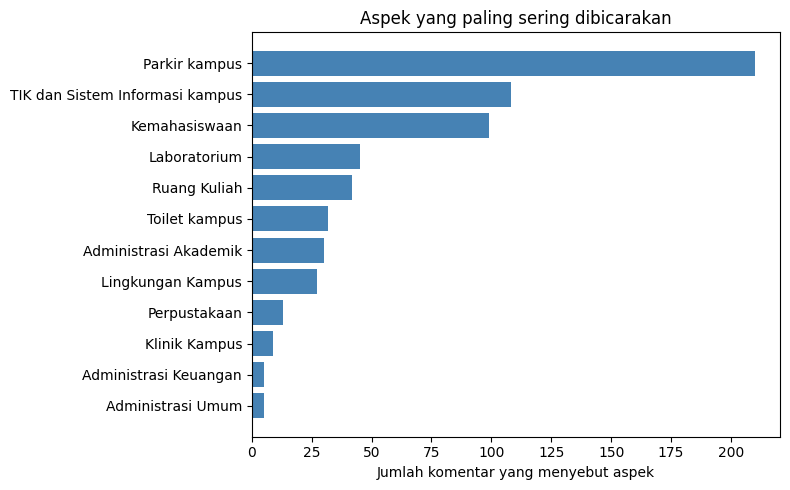

In [18]:
plt.figure(figsize=(8, 5))
plt.barh(df_frekuensi["aspek"][::-1], df_frekuensi["frekuensi"][::-1], color="steelblue")
plt.xlabel("Jumlah komentar yang menyebut aspek")
plt.title("Aspek yang paling sering dibicarakan")
plt.tight_layout()
plt.show()

### Kata yang paling sering muncul

In [19]:
semua_token = []
for token in df_teks["token"]:
    semua_token.extend(token)

df_kata = pd.DataFrame(Counter(semua_token).most_common(30), columns=["kata", "frekuensi"])
df_kata

,kata,frekuensi
0,parkir,385
1,mahasiswa,140
2,baik,98
3,lebih,95
4,banyak,94
5,wifi,94
6,tempat,84
7,tingkat,79
8,tambah,75
9,kurang,75


### Simpan hasil

In [20]:
# 1. teks bersih + aspek per komentar
df_simpan = df_teks[["response_id", "teks_komentar", "teks_bersih"]].copy()
df_simpan["aspek"] = df_teks["aspek"].apply(lambda a: "; ".join(a))
df_simpan.to_csv(ANALYTICS_DIR / "teks_bersih_mahasiswa.csv", index=False)

# 2. format long: satu baris per (komentar, aspek)
baris_long = []
for _, baris in df_teks.iterrows():
    for aspek in baris["aspek"]:
        baris_long.append({"response_id": baris["response_id"], "aspek": aspek})
pd.DataFrame(baris_long).to_csv(ANALYTICS_DIR / "aspek_komentar_mahasiswa.csv", index=False)

# 3. frekuensi aspek (dipakai priority analysis)
df_frekuensi.to_csv(ANALYTICS_DIR / "frekuensi_aspek_mahasiswa.csv", index=False)

print("Tersimpan di:", ANALYTICS_DIR)

Tersimpan di: c:\KULIAH\SEM 5\Project Analitika Data\data\analytics
